# Sales Data Analysis (Python)

**Author:** Siddique Shaikh | **Tools:** Python, Pandas, Matplotlib, Seaborn

## Objective
Clean a retail sales dataset and use exploratory data analysis (EDA) to answer business questions:

1. How are we doing overall? (Sales, Profit, Orders)
2. Which **products, categories and regions** perform best, and which lose money?
3. How do **monthly sales trends** and seasonality look?
4. Does **discounting** help or hurt profit?
5. What should the business do next?

## Dataset
Retail "Superstore" sales data: one row per order line, with order/ship dates, customer segment, location, product category, sales, quantity, discount and profit.

## 1. Setup

In [5]:
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid", palette="deep")
plt.rcParams["figure.figsize"] = (10, 5)
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["axes.titleweight"] = "bold"

os.makedirs("charts", exist_ok=True)   # all charts are saved here (handy for GitHub)

def money(x, pos=None):
    """Format numbers like $1.2K / $3.4M on chart axes."""
    sign = "-" if x < 0 else ""
    x = abs(x)
    if x >= 1e6: return f"{sign}${x/1e6:.1f}M"
    if x >= 1e3: return f"{sign}${x/1e3:.0f}K"
    return f"{sign}${x:.0f}"

## 2. Load the data

In [6]:
# Change this to YOUR file name. Both Excel (.xls / .xlsx) and .csv files work.
DATA_PATH = r"C:\Users\siddi\OneDrive\Desktop\Sales data analysis\archive\SuperStoreData-230102-093001.xlsx"

if DATA_PATH.lower().endswith((".xls", ".xlsx")):
    xl = pd.ExcelFile(DATA_PATH)
    print("Sheets found in the file:", xl.sheet_names)
    # Use the "Orders" sheet if there is one, otherwise the first sheet
    sheet = "Orders" if "Orders" in xl.sheet_names else xl.sheet_names[0]
    print("Using sheet:", sheet)
    df = xl.parse(sheet)
else:
    df = pd.read_csv(DATA_PATH, encoding="latin-1")   # latin-1 avoids encoding errors

# Newer versions of this dataset use slightly different column names. Make them consistent.
df.columns = df.columns.astype(str).str.strip()
df = df.rename(columns={"State/Province": "State", "Country/Region": "Country"})

# Safety check: make sure the columns this analysis needs are present
needed = ["Order ID", "Order Date", "Ship Date", "Customer ID", "Segment", "State", "Region", "Postal Code",
          "Category", "Sub-Category", "Product Name", "Sales", "Quantity", "Discount", "Profit"]
missing_cols = [c for c in needed if c not in df.columns]
if missing_cols:
    print("\nMISSING COLUMNS:", missing_cols)
    print("Columns in your file:", list(df.columns))
    raise KeyError("Your file has different column names. Send this output to Claude to adjust the notebook.")

print("Rows, Columns:", df.shape)
df.head()

Sheets found in the file: ['Orders']
Using sheet: Orders
Rows, Columns: (9994, 21)


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,...,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit
0,1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.9600,2,0.00,41.9136
1,2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,...,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs,...",731.9400,3,0.00,219.5820
2,3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,...,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters b...,14.6200,2,0.00,6.8714
3,4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.0310
4,5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,...,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.3680,2,0.20,2.5164


## 3. First look at the data

In [7]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 9994 entries, 0 to 9993
Data columns (total 21 columns):
 #   Column         Non-Null Count  Dtype         
---  ------         --------------  -----         
 0   Row ID         9994 non-null   int64         
 1   Order ID       9994 non-null   str           
 2   Order Date     9994 non-null   datetime64[us]
 3   Ship Date      9994 non-null   datetime64[us]
 4   Ship Mode      9994 non-null   str           
 5   Customer ID    9994 non-null   str           
 6   Customer Name  9994 non-null   str           
 7   Segment        9994 non-null   str           
 8   Country        9994 non-null   str           
 9   City           9994 non-null   str           
 10  State          9994 non-null   str           
 11  Postal Code    9994 non-null   int64         
 12  Region         9994 non-null   str           
 13  Product ID     9994 non-null   str           
 14  Category       9994 non-null   str           
 15  Sub-Category   9994 non-null   s

In [8]:
df.describe().round(2)

,Row ID,Order Date,Ship Date,Postal Code,Sales,Quantity,Discount,Profit
count,9994.00,9994,9994,9994.00,9994.00,9994.00,9994.00,9994.00
mean,4997.50,2016-04-30 00:07:12.259355,2016-05-03 23:06:58.571142,55190.38,229.86,3.79,0.16,28.66
min,1.00,2014-01-03 00:00:00,2014-01-07 00:00:00,1040.00,0.44,1.00,0.00,-6599.98
25%,2499.25,2015-05-23 00:00:00,2015-05-27 00:00:00,23223.00,17.28,2.00,0.00,1.73
50%,4997.50,2016-06-26 00:00:00,2016-06-29 00:00:00,56430.50,54.49,3.00,0.20,8.67
75%,7495.75,2017-05-14 00:00:00,2017-05-18 00:00:00,90008.00,209.94,5.00,0.20,29.36
max,9994.00,2017-12-30 00:00:00,2018-01-05 00:00:00,99301.00,22638.48,14.00,0.80,8399.98
std,2885.16,NaN,NaN,32063.69,623.25,2.23,0.21,234.26


## 4. Data cleaning
Real data is never perfect. Steps: remove duplicates, handle missing values, fix data types (dates), tidy text, and create new columns we need for analysis.

In [9]:
rows_before = len(df)

# 4.1 Duplicates
dupes = df.duplicated().sum()
df = df.drop_duplicates().reset_index(drop=True)
print(f"Duplicate rows removed: {dupes}  ({rows_before} -> {len(df)} rows)")

# 4.2 Missing values (before)
missing = df.isna().sum()
print("\nMissing values before cleaning:")
print(missing[missing > 0] if missing.sum() else "None")

Duplicate rows removed: 0  (9994 -> 9994 rows)

Missing values before cleaning:
None


In [10]:
# 4.3 Handle missing values
# Postal Code is an identifier (not a number to calculate with) so keep it as text.
df["Postal Code"] = df["Postal Code"].astype("string").str.replace(r"\.0$", "", regex=True).fillna("Unknown")
df["Segment"] = df["Segment"].fillna("Unknown")

# 4.4 Fix data types: dates must be real dates, not text
df["Order Date"] = pd.to_datetime(df["Order Date"], format="mixed")   # works for Excel dates and CSV text dates
df["Ship Date"]  = pd.to_datetime(df["Ship Date"],  format="mixed")

# 4.5 Tidy text columns (remove stray spaces)
for col in df.select_dtypes(include=["object", "string"]).columns:
    df[col] = df[col].astype("string").str.strip()

print("Missing values after cleaning:", int(df.isna().sum().sum()))

Missing values after cleaning: 0


In [11]:
# 4.6 Feature engineering: new columns that make analysis easier
df["Year"]          = df["Order Date"].dt.year
df["Month"]         = df["Order Date"].dt.month
df["Month Name"]    = df["Order Date"].dt.strftime("%b")
df["YearMonth"]     = df["Order Date"].dt.to_period("M")
df["Shipping Days"] = (df["Ship Date"] - df["Order Date"]).dt.days
df["Profit Margin %"] = (df["Profit"] / df["Sales"] * 100).round(2)

df[["Order Date", "Year", "Month Name", "Shipping Days", "Sales", "Profit", "Profit Margin %"]].head()

,Order Date,Year,Month Name,Shipping Days,Sales,Profit,Profit Margin %
0,2016-11-08,2016,Nov,3,261.9600,41.9136,16.00
1,2016-11-08,2016,Nov,3,731.9400,219.5820,30.00
2,2016-06-12,2016,Jun,4,14.6200,6.8714,47.00
3,2015-10-11,2015,Oct,7,957.5775,-383.0310,-40.00
4,2015-10-11,2015,Oct,7,22.3680,2.5164,11.25


## 5. Key performance indicators (KPIs)

In [12]:
total_sales   = df["Sales"].sum()
total_profit  = df["Profit"].sum()
total_orders  = df["Order ID"].nunique()
customers     = df["Customer ID"].nunique()
avg_order_val = total_sales / total_orders
overall_margin = total_profit / total_sales * 100

kpis = pd.DataFrame({
    "KPI": ["Total Sales", "Total Profit", "Profit Margin", "Total Orders", "Unique Customers", "Avg Order Value", "Avg Shipping Days"],
    "Value": [f"${total_sales:,.0f}", f"${total_profit:,.0f}", f"{overall_margin:.1f}%", f"{total_orders:,}",
              f"{customers:,}", f"${avg_order_val:,.2f}", f"{df['Shipping Days'].mean():.1f}"]
})
kpis

,KPI,Value
0,Total Sales,"$2,297,201"
1,Total Profit,"$286,397"
2,Profit Margin,12.5%
3,Total Orders,"5,009"
4,Unique Customers,793
5,Avg Order Value,$458.61
6,Avg Shipping Days,4.0


## 6. Top-performing products

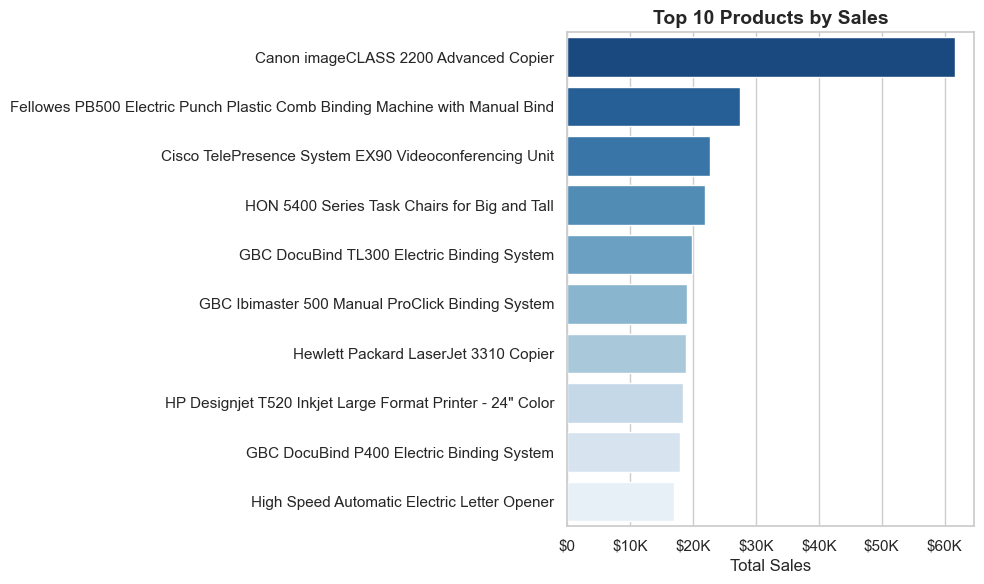

,Sales,Profit
Product Name,,
Canon imageCLASS 2200 Advanced Copier,61599.82,25199.93
Fellowes PB500 Electric Punch Plastic Comb Binding Machine with Manual Bind,27453.38,7753.04
Cisco TelePresence System EX90 Videoconferencing Unit,22638.48,-1811.08
HON 5400 Series Task Chairs for Big and Tall,21870.58,0.00
GBC DocuBind TL300 Electric Binding System,19823.48,2233.51
GBC Ibimaster 500 Manual ProClick Binding System,19024.50,760.98
Hewlett Packard LaserJet 3310 Copier,18839.69,6983.88
"HP Designjet T520 Inkjet Large Format Printer - 24"" Color",18374.90,4094.98
GBC DocuBind P400 Electric Binding System,17965.07,-1878.17


In [13]:
top_products = (df.groupby("Product Name")[["Sales", "Profit"]].sum()
                  .sort_values("Sales", ascending=False).head(10))

fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top_products["Sales"], y=top_products.index, hue=top_products.index, palette="Blues_r", legend=False, ax=ax)
ax.xaxis.set_major_formatter(plt.FuncFormatter(money))
ax.set_title("Top 10 Products by Sales"); ax.set_xlabel("Total Sales"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("charts/01_top_products.png", dpi=150, bbox_inches="tight"); plt.show()

top_products.round(2)

## 7. Category and sub-category performance

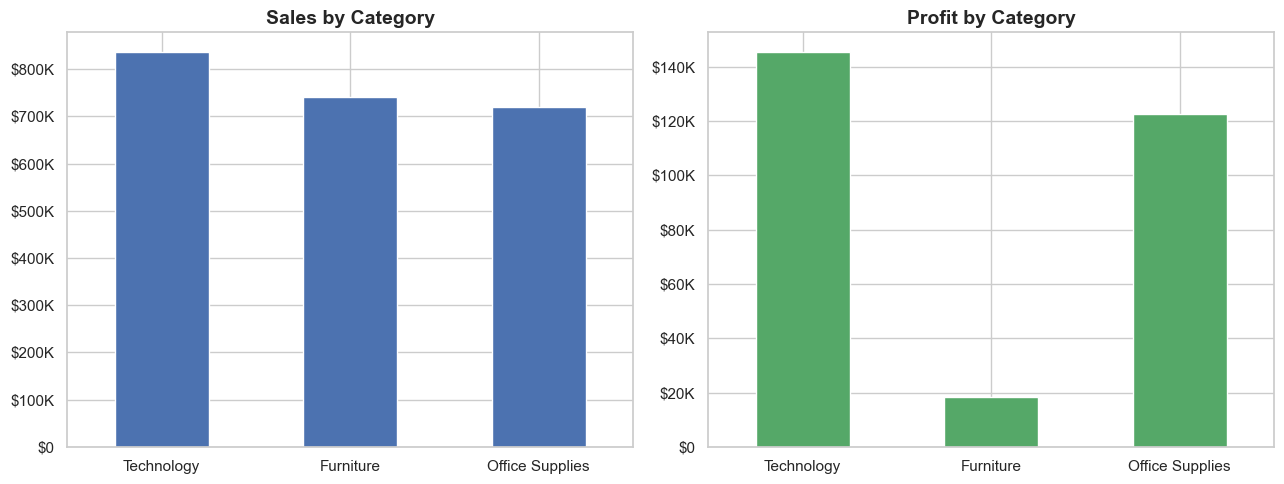

,Sales,Profit,Margin %
Category,,,
Technology,836154.03,145454.95,17.4
Furniture,741999.80,18451.27,2.5
Office Supplies,719047.03,122490.80,17.0


In [14]:
cat = df.groupby("Category")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
cat["Margin %"] = (cat["Profit"] / cat["Sales"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
cat["Sales"].plot(kind="bar", ax=axes[0], color=sns.color_palette("deep")[0], rot=0)
axes[0].set_title("Sales by Category"); axes[0].set_xlabel(""); axes[0].yaxis.set_major_formatter(plt.FuncFormatter(money))
cat["Profit"].plot(kind="bar", ax=axes[1], color=sns.color_palette("deep")[2], rot=0)
axes[1].set_title("Profit by Category"); axes[1].set_xlabel(""); axes[1].yaxis.set_major_formatter(plt.FuncFormatter(money))
plt.tight_layout(); plt.savefig("charts/02_category.png", dpi=150, bbox_inches="tight"); plt.show()
cat.round(2)

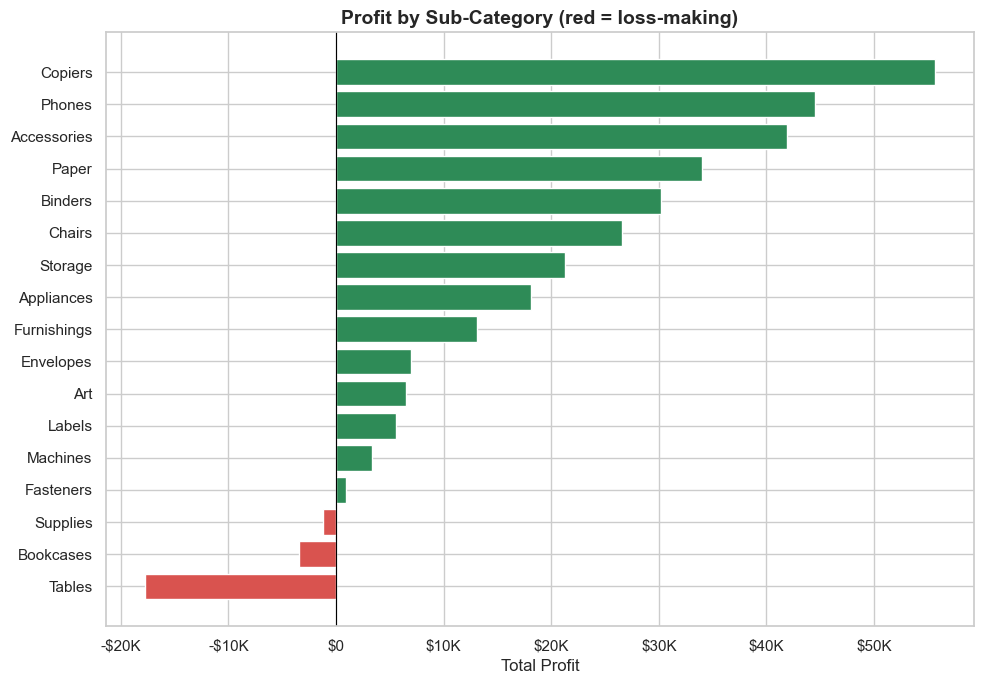

Loss-making sub-categories: ['Tables', 'Bookcases', 'Supplies']


In [15]:
sub = df.groupby("Sub-Category")[["Sales", "Profit"]].sum().sort_values("Profit")

colors = ["#d9534f" if p < 0 else "#2e8b57" for p in sub["Profit"]]   # red = losing money, green = profitable
fig, ax = plt.subplots(figsize=(10, 7))
ax.barh(sub.index, sub["Profit"], color=colors)
ax.axvline(0, color="black", linewidth=0.8)
ax.xaxis.set_major_formatter(plt.FuncFormatter(money))
ax.set_title("Profit by Sub-Category (red = loss-making)"); ax.set_xlabel("Total Profit")
plt.tight_layout(); plt.savefig("charts/03_subcategory_profit.png", dpi=150, bbox_inches="tight"); plt.show()

loss_makers = sub[sub["Profit"] < 0]
print("Loss-making sub-categories:", list(loss_makers.index) if len(loss_makers) else "None")

## 8. Regional performance

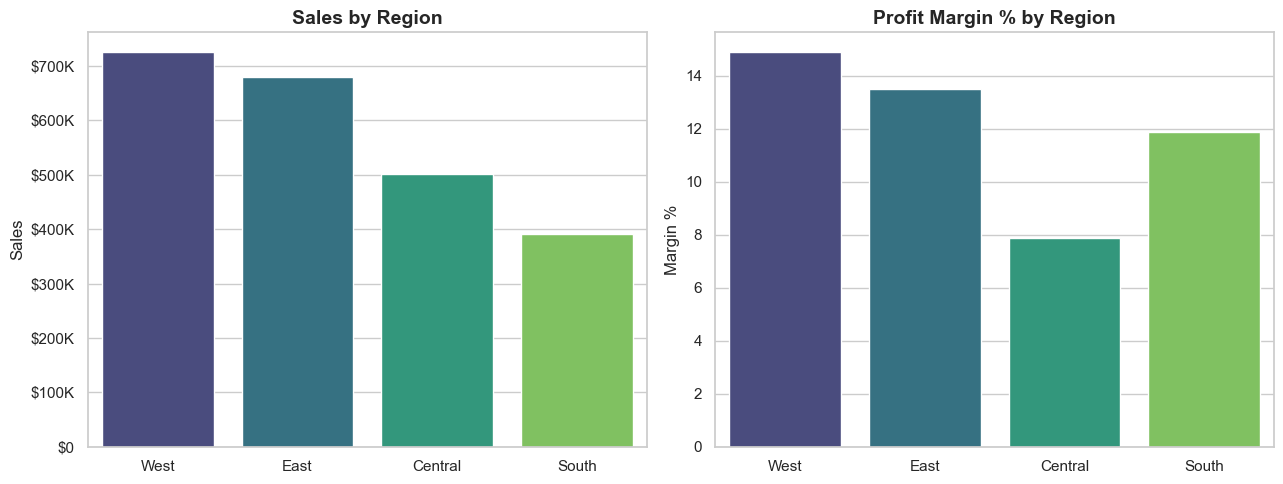

,Sales,Profit,Margin %
Region,,,
West,725457.82,108418.45,14.9
East,678781.24,91522.78,13.5
Central,501239.89,39706.36,7.9
South,391721.90,46749.43,11.9


In [16]:
reg = df.groupby("Region")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
reg["Margin %"] = (reg["Profit"] / reg["Sales"] * 100).round(1)

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sns.barplot(x=reg.index, y=reg["Sales"], hue=reg.index, palette="viridis", legend=False, ax=axes[0])
axes[0].set_title("Sales by Region"); axes[0].set_xlabel(""); axes[0].yaxis.set_major_formatter(plt.FuncFormatter(money))
sns.barplot(x=reg.index, y=reg["Margin %"], hue=reg.index, palette="viridis", legend=False, ax=axes[1])
axes[1].set_title("Profit Margin % by Region"); axes[1].set_xlabel("")
plt.tight_layout(); plt.savefig("charts/04_region.png", dpi=150, bbox_inches="tight"); plt.show()
reg.round(2)

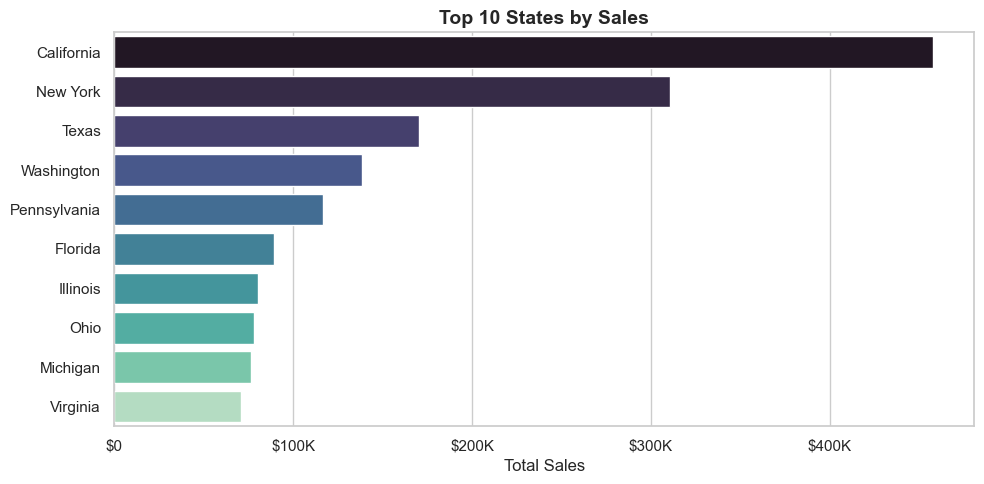

In [17]:
state = df.groupby("State")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False).head(10)
fig, ax = plt.subplots(figsize=(10, 5))
sns.barplot(x=state["Sales"], y=state.index, hue=state.index, palette="mako", legend=False, ax=ax)
ax.xaxis.set_major_formatter(plt.FuncFormatter(money))
ax.set_title("Top 10 States by Sales"); ax.set_xlabel("Total Sales"); ax.set_ylabel("")
plt.tight_layout(); plt.savefig("charts/05_top_states.png", dpi=150, bbox_inches="tight"); plt.show()

## 9. Monthly sales trends and seasonality
Here we look at how sales move over time, which months are strongest, and how each year compares.

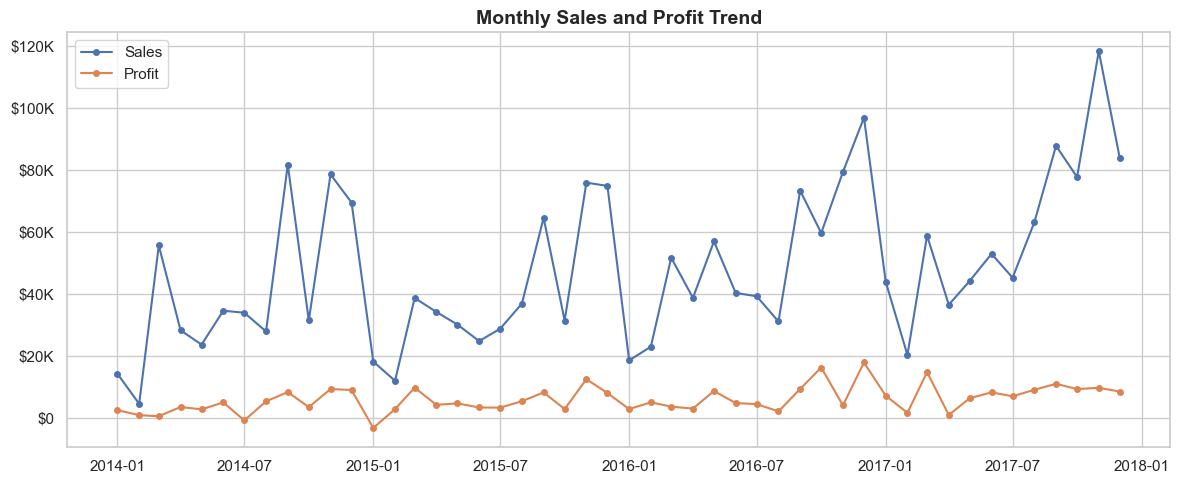

In [18]:
monthly = df.groupby("YearMonth")[["Sales", "Profit"]].sum()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(monthly.index, monthly["Sales"], marker="o", markersize=4, label="Sales")
ax.plot(monthly.index, monthly["Profit"], marker="o", markersize=4, label="Profit")
ax.yaxis.set_major_formatter(plt.FuncFormatter(money))
ax.set_title("Monthly Sales and Profit Trend"); ax.set_xlabel(""); ax.legend()
plt.tight_layout(); plt.savefig("charts/06_monthly_trend.png", dpi=150, bbox_inches="tight"); plt.show()

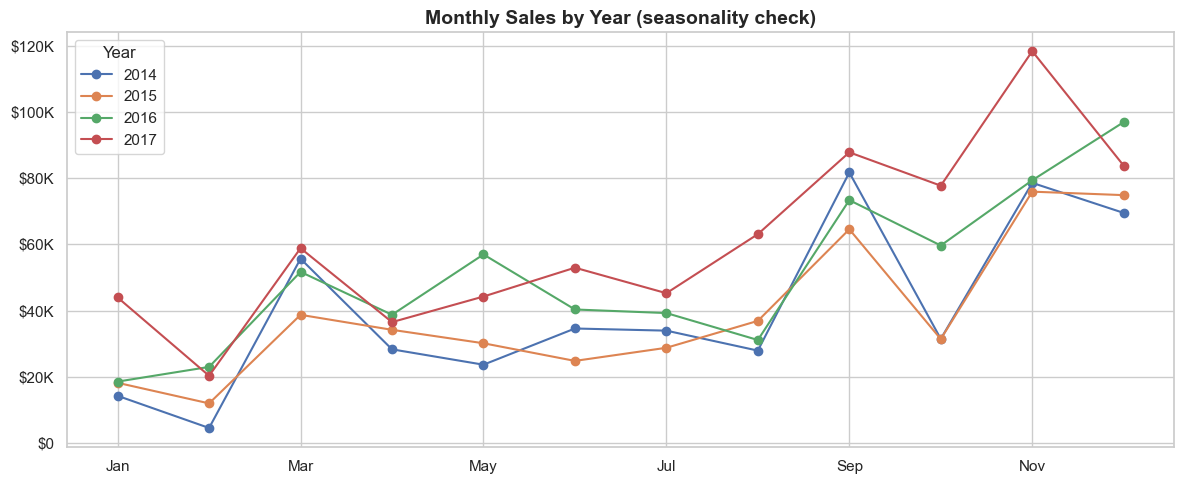

,Sales,Profit,Sales Growth %
Year,,,
2014,484247.50,49543.97,NaN
2015,470532.51,61618.60,-2.8
2016,609205.60,81795.17,29.5
2017,733215.26,93439.27,20.4


In [19]:
month_order = ["Jan","Feb","Mar","Apr","May","Jun","Jul","Aug","Sep","Oct","Nov","Dec"]
pivot = df.pivot_table(index="Month Name", columns="Year", values="Sales", aggfunc="sum").reindex(month_order)

fig, ax = plt.subplots(figsize=(12, 5))
pivot.plot(ax=ax, marker="o")
ax.yaxis.set_major_formatter(plt.FuncFormatter(money))
ax.set_title("Monthly Sales by Year (seasonality check)"); ax.set_xlabel(""); ax.legend(title="Year")
plt.tight_layout(); plt.savefig("charts/07_seasonality.png", dpi=150, bbox_inches="tight"); plt.show()

yearly = df.groupby("Year")[["Sales", "Profit"]].sum()
yearly["Sales Growth %"] = (yearly["Sales"].pct_change() * 100).round(1)
yearly.round(2)

## 10. Does discounting hurt profit?
Discounts can attract buyers, but deep discounts can destroy margins. Let's test it.

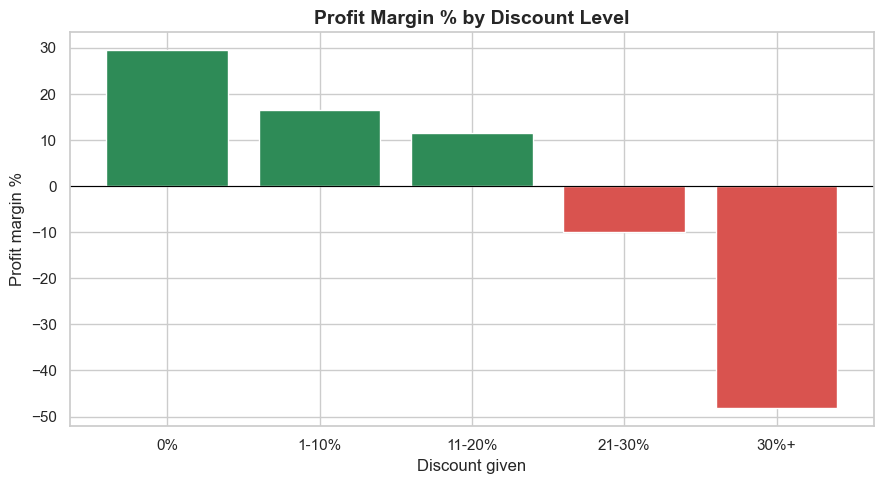

,Orders,Sales,Profit,Margin %
Discount Band,,,,
0%,4798,1087908.47,320987.60,29.5
1-10%,94,54369.35,9029.18,16.6
11-20%,3709,792152.89,91756.30,11.6
21-30%,227,103226.66,-10369.28,-10.0
30%+,1166,259543.49,-125006.78,-48.2


In [20]:
df["Discount Band"] = pd.cut(df["Discount"], bins=[-0.01, 0, 0.1, 0.2, 0.3, 1.0],
                             labels=["0%", "1-10%", "11-20%", "21-30%", "30%+"])
disc = df.groupby("Discount Band", observed=True).agg(Orders=("Order ID", "count"), Sales=("Sales", "sum"), Profit=("Profit", "sum"))
disc["Margin %"] = (disc["Profit"] / disc["Sales"] * 100).round(1)

fig, ax = plt.subplots(figsize=(9, 5))
colors = ["#d9534f" if m < 0 else "#2e8b57" for m in disc["Margin %"]]
ax.bar(disc.index.astype(str), disc["Margin %"], color=colors)
ax.axhline(0, color="black", linewidth=0.8)
ax.set_title("Profit Margin % by Discount Level"); ax.set_xlabel("Discount given"); ax.set_ylabel("Profit margin %")
plt.tight_layout(); plt.savefig("charts/08_discount_margin.png", dpi=150, bbox_inches="tight"); plt.show()
disc.round(2)

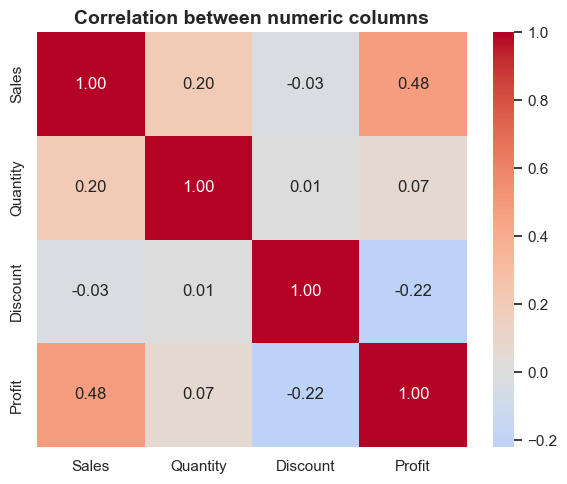

In [21]:
corr = df[["Sales", "Quantity", "Discount", "Profit"]].corr()
fig, ax = plt.subplots(figsize=(6, 5))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=ax)
ax.set_title("Correlation between numeric columns")
plt.tight_layout(); plt.savefig("charts/09_correlation.png", dpi=150, bbox_inches="tight"); plt.show()

## 11. Customer segment view

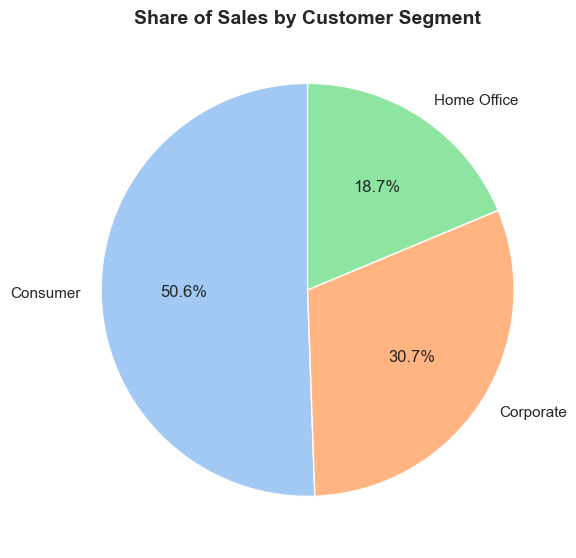

,Sales,Profit,Share of Sales %
Segment,,,
Consumer,1161401.34,134119.21,50.6
Corporate,706146.37,91979.13,30.7
Home Office,429653.15,60298.68,18.7


In [22]:
seg = df.groupby("Segment")[["Sales", "Profit"]].sum().sort_values("Sales", ascending=False)
seg["Share of Sales %"] = (seg["Sales"] / seg["Sales"].sum() * 100).round(1)

fig, ax = plt.subplots(figsize=(6, 6))
ax.pie(seg["Sales"], labels=seg.index, autopct="%1.1f%%", startangle=90, colors=sns.color_palette("pastel"))
ax.set_title("Share of Sales by Customer Segment")
plt.tight_layout(); plt.savefig("charts/10_segment_share.png", dpi=150, bbox_inches="tight"); plt.show()
seg.round(2)

## 12. Key findings
The summary below is **generated from the data**, so it stays correct whichever dataset you load. Copy these into your own words for your README and interviews.

In [23]:
best_cat      = cat["Sales"].idxmax()
best_cat_marg = cat["Margin %"].idxmax()
best_region   = reg["Sales"].idxmax()
best_reg_marg = reg["Margin %"].idxmax()
weak_reg      = reg["Margin %"].idxmin()
best_month    = df.groupby("Month Name")["Sales"].sum().idxmax()
worst_month   = df.groupby("Month Name")["Sales"].sum().idxmin()
top_product   = top_products["Sales"].idxmax()
best_year     = yearly["Sales"].idxmax()
hi_disc = df.loc[df["Discount"] >= 0.3]
no_disc = df.loc[df["Discount"] == 0]
hi_margin = hi_disc["Profit"].sum() / hi_disc["Sales"].sum() * 100
no_margin = no_disc["Profit"].sum() / no_disc["Sales"].sum() * 100

print(f"1. Overall: ${total_sales:,.0f} in sales and ${total_profit:,.0f} profit ({overall_margin:.1f}% margin) across {total_orders:,} orders.")
print(f"2. '{best_cat}' drives the most sales; '{best_cat_marg}' has the best profit margin.")
print(f"3. Top product by sales: '{top_product}'.")
print(f"4. Loss-making sub-categories: {', '.join(loss_makers.index) if len(loss_makers) else 'none'}.")
print(f"5. '{best_region}' is the biggest region by sales; '{best_reg_marg}' has the best margin and '{weak_reg}' the weakest.")
print(f"6. Sales peak in {best_month} and are lowest in {worst_month}; {best_year} was the strongest year.")
print(f"7. Orders with 30%+ discount earn a {hi_margin:.1f}% margin versus {no_margin:.1f}% with no discount.")

1. Overall: $2,297,201 in sales and $286,397 profit (12.5% margin) across 5,009 orders.
2. 'Technology' drives the most sales; 'Technology' has the best profit margin.
3. Top product by sales: 'Canon imageCLASS 2200 Advanced Copier'.
4. Loss-making sub-categories: Tables, Bookcases, Supplies.
5. 'West' is the biggest region by sales; 'West' has the best margin and 'Central' the weakest.
6. Sales peak in Nov and are lowest in Feb; 2017 was the strongest year.
7. Orders with 30%+ discount earn a -37.3% margin versus 29.5% with no discount.


## 13. Business recommendations
Use your own findings above to fill these in (examples of the kind of recommendation to make):

- **Fix or reprice loss-making sub-categories**: review supplier cost and discounting for anything in red on the sub-category chart.
- **Cap deep discounts**: if high-discount orders show a much lower (or negative) margin, set approval rules for discounts above ~20-30%.
- **Plan inventory and marketing around peak months** found in the seasonality chart.
- **Invest in the strongest region and segment, and investigate the weakest margin region.**

## 14. Conclusion
This project covered the full analyst workflow: loading and inspecting data, cleaning (duplicates, missing values, dates), feature engineering, KPI calculation, and visual EDA that turns numbers into business recommendations.

**Skills demonstrated:** Pandas (groupby, pivot_table, datetime, cut), Matplotlib, Seaborn, data cleaning, business storytelling.